
RELATIVE CHANGES FROM K = 300
strategy_id     K  irrigation_mean  yield_mean  irrigation_change_pct  yield_change_pct
         S1   300         695.9976     45.6833                 0.0000            0.0000
         S1  1000         698.2474     45.7768                 0.3232            0.2048
         S1  5000         695.6483     45.6513                 0.0502            0.0700
         S1 10000         696.5674     45.6593                 0.0819            0.0525
         S2   300        1729.6771     76.0083                 0.0000            0.0000
         S2  1000        1736.8015     76.1941                 0.4119            0.2443
         S2  5000        1730.3788     75.9773                 0.0406            0.0408
         S2 10000        1732.6479     75.9669                 0.1718            0.0546
         S3   300        3186.1567    100.1119                 0.0000            0.0000
         S3  1000        3190.2646    100.0828                 0.1289            0.0290
 

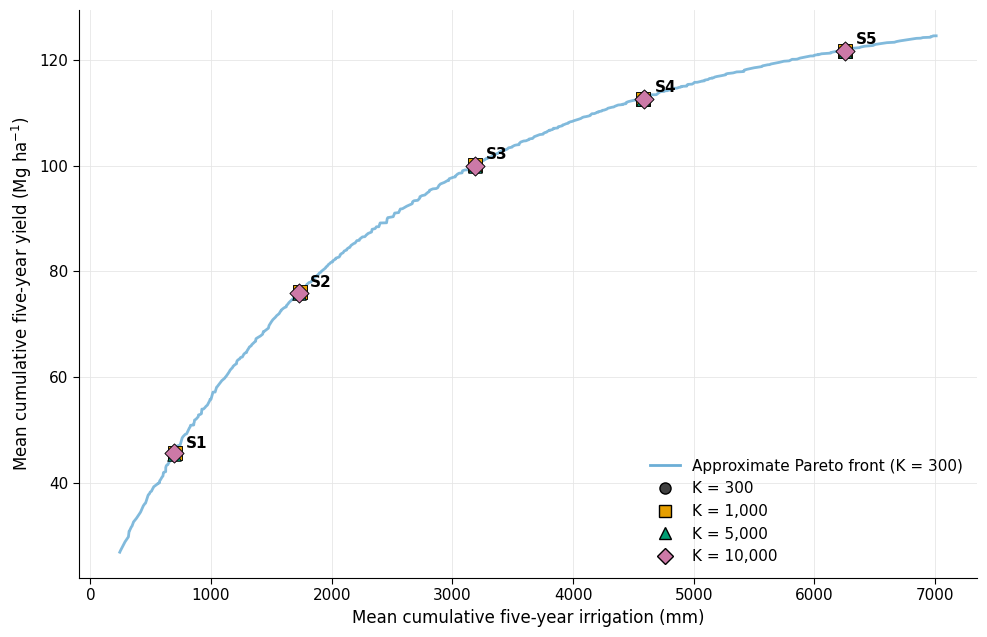

In [1]:
# Figure S13: Post-optimization stability of representative strategies

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

pareto_df = pd.read_csv(
    "NSGA2_K300_P100_G100_S101/final_pareto_archive_from_all_population.csv"
).sort_values("irr_mean")

df = pd.read_csv(
    "Reevaluation_Selected_Strategies_K1000_5000_10000/"
    "K300_K1000_K5000_K10000_plot_data.csv"
)

strategy_order = ["S1", "S2", "S3", "S4", "S5"]
K_order = [300, 1000, 5000, 10000]

df["K"] = pd.to_numeric(df["K"])
df["strategy_id"] = df["strategy_id"].astype(str)
df = df.sort_values(["strategy_id", "K"]).reset_index(drop=True)

baseline = df[df["K"] == 300].set_index("strategy_id")

for variable in ["irrigation", "yield"]:
    df[f"{variable}_change_pct"] = (
        (df[f"{variable}_mean"] - df["strategy_id"].map(baseline[f"{variable}_mean"])).abs()
        / df["strategy_id"].map(baseline[f"{variable}_mean"]).abs() * 100
    )

results = df[
    ["strategy_id", "K", "irrigation_mean", "yield_mean",
     "irrigation_change_pct", "yield_change_pct"]
]

print("\nRELATIVE CHANGES FROM K = 300")
print(results.round(4).to_string(index=False))

larger = df[df["K"] > 300]
k10000 = df[df["K"] == 10000]

print("\nALL LARGER ENSEMBLES (K = 1,000, 5,000, 10,000)")
print(f"Maximum irrigation change: {larger['irrigation_change_pct'].max():.4f}%")
print(f"Maximum yield change: {larger['yield_change_pct'].max():.4f}%")

print("\nAT K = 10,000")
for variable in ["irrigation", "yield"]:
    values = k10000[f"{variable}_change_pct"]
    print(f"{variable.capitalize()} change range: {values.min():.4f}% to {values.max():.4f}%")

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 11,
    "axes.labelsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "axes.linewidth": 0.8,
})

marker_map = {300: "o", 1000: "s", 5000: "^", 10000: "D"}
color_map = {
    300: "#404040",
    1000: "#E69F00",
    5000: "#009E73",
    10000: "#CC79A7",
}

fig, ax = plt.subplots(figsize=(10, 6.5))

ax.plot(
    pareto_df["irr_mean"], pareto_df["yld_mean"],
    color="#6BAED6", linewidth=2, alpha=0.85, zorder=1
)

for strategy in strategy_order:
    d = df[df["strategy_id"] == strategy].sort_values("K")

    for K in K_order:
        point = d[d["K"] == K]
        if point.empty:
            continue

        ax.scatter(
            point["irrigation_mean"], point["yield_mean"],
            marker=marker_map[K], s=95, color=color_map[K],
            edgecolor="black", linewidth=0.65,
            zorder=2 + K_order.index(K)
        )

    original = d[d["K"] == 300]
    if not original.empty:
        ax.annotate(
            strategy,
            (original["irrigation_mean"].iloc[0], original["yield_mean"].iloc[0]),
            xytext=(8, 4), textcoords="offset points",
            fontsize=11, fontweight="bold"
        )

ax.set_xlabel("Mean cumulative five-year irrigation (mm)")
ax.set_ylabel("Mean cumulative five-year yield (Mg ha$^{-1}$)")
ax.grid(axis="both", color="0.90", linewidth=0.6)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(direction="out", length=4)

handles = [
    Line2D([0], [0], color="#6BAED6", linewidth=2,
           label="Approximate Pareto front (K = 300)")
]

for K in K_order:
    handles.append(
        Line2D(
            [0], [0], marker=marker_map[K], color="none",
            markerfacecolor=color_map[K], markeredgecolor="black",
            markersize=8, linestyle="None", label=f"K = {K:,}"
        )
    )

ax.legend(handles=handles, loc="lower right", frameon=False, fontsize=11)

fig.tight_layout()
plt.show()


NSGA-II OPTIMIZATION CONVERGENCE

PARETO-FRONT PROGRESSION
Generation  20:  100 nondominated solutions
Generation  40:  100 nondominated solutions
Generation  60:  100 nondominated solutions
Generation  80:  100 nondominated solutions
Generation 100:  100 nondominated solutions

CUMULATIVE PARETO ARCHIVE COMPARISON
 Generations  Archive size  Unique nondominated points  Hypervolume
         100           568                         558   584025.375
         200          1059                        1033   586368.306

Archive size increase: 86.44%
Hypervolume increase: 0.401%

COMMON HYPERVOLUME REFERENCE POINT
Irrigation: 7386.3622 mm
Negative yield: -15.7352 Mg ha^-1
Equivalent yield: 15.7352 Mg ha^-1

OBJECTIVE RANGES USED FOR REFERENCE POINT
Irrigation: 118.6701 to 7040.2817
Negative yield: -124.4833 to -20.9137


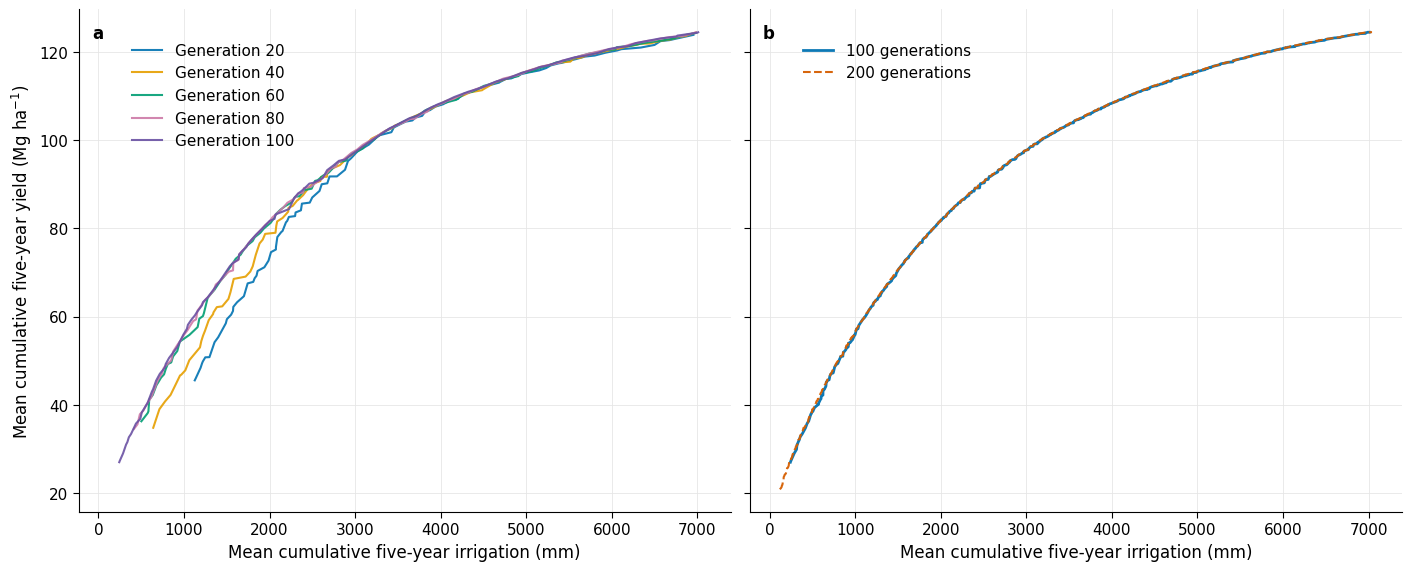

In [2]:
# Figure S14: NSGA-II optimization convergence

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pymoo.indicators.hv import HV
from pymoo.util.nds.non_dominated_sorting import NonDominatedSorting

gen100_dir = Path("NSGA2_K300_P100_G100_S101")
gen200_dir = Path("NSGA2_K300_P100_G200_S101")
generations = [20, 40, 60, 80, 100]

def clean(df):
    for col in ["irr_mean", "yld_mean"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    return df.dropna(subset=["irr_mean", "yld_mean"]).sort_values("irr_mean").reset_index(drop=True)

def objectives(df):
    return np.column_stack([df["irr_mean"], -df["yld_mean"]])

def hv_points(df):
    df = df.drop_duplicates(subset=["irr_mean", "yld_mean"])
    idx = NonDominatedSorting().do(objectives(df), only_non_dominated_front=True)
    return df.iloc[idx].reset_index(drop=True)

archive100 = clean(pd.read_csv(gen100_dir / "final_pareto_archive_from_all_population.csv"))
archive200 = clean(pd.read_csv(gen200_dir / "final_pareto_archive_from_all_population.csv"))

fronts = {
    g: clean(pd.read_csv(gen100_dir / "pareto_by_generation" / f"pareto_gen_{g:03d}.csv"))
    for g in generations
}

hv_archive100 = hv_points(archive100)
hv_archive200 = hv_points(archive200)

F100 = objectives(hv_archive100)
F200 = objectives(hv_archive200)
Fcombined = np.vstack([F100, F200])

fmin = Fcombined.min(axis=0)
fmax = Fcombined.max(axis=0)
reference_point = fmax + 0.05 * np.maximum(fmax - fmin, 1e-12)

hv = HV(ref_point=reference_point)
hv100, hv200 = float(hv(F100)), float(hv(F200))

n100, n200 = len(archive100), len(archive200)
archive_change = (n200 - n100) / n100 * 100
hv_change = (hv200 - hv100) / hv100 * 100

print("\nNSGA-II OPTIMIZATION CONVERGENCE")
print("=" * 65)

print("\nPARETO-FRONT PROGRESSION")
for g in generations:
    print(f"Generation {g:3d}: {len(fronts[g]):4d} nondominated solutions")

summary = pd.DataFrame({
    "Generations": [100, 200],
    "Archive size": [n100, n200],
    "Unique nondominated points": [len(hv_archive100), len(hv_archive200)],
    "Hypervolume": [hv100, hv200]
})

print("\nCUMULATIVE PARETO ARCHIVE COMPARISON")
print(summary.to_string(index=False, float_format="%.3f"))

print(f"\nArchive size increase: {archive_change:.2f}%")
print(f"Hypervolume increase: {hv_change:.3f}%")

print("\nCOMMON HYPERVOLUME REFERENCE POINT")
print(f"Irrigation: {reference_point[0]:.4f} mm")
print(f"Negative yield: {reference_point[1]:.4f} Mg ha^-1")
print(f"Equivalent yield: {-reference_point[1]:.4f} Mg ha^-1")

print("\nOBJECTIVE RANGES USED FOR REFERENCE POINT")
print(f"Irrigation: {fmin[0]:.4f} to {fmax[0]:.4f}")
print(f"Negative yield: {fmin[1]:.4f} to {fmax[1]:.4f}")

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 11,
    "axes.labelsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "axes.linewidth": 0.8
})

colors = {
    20: "#0072B2",
    40: "#E69F00",
    60: "#009E73",
    80: "#CC79A7",
    100: "#6A51A3"
}

fig, axes = plt.subplots(
    1, 2, figsize=(14, 5.6),
    sharex=True, sharey=True, constrained_layout=True
)

# (a) Pareto-front progression
ax = axes[0]

for g in generations:
    d = fronts[g]
    ax.plot(
        d["irr_mean"], d["yld_mean"],
        color=colors[g], linewidth=1.5, alpha=0.9,
        label=f"Generation {g}"
    )

ax.legend(loc="upper left", bbox_to_anchor=(0.06, 0.96), frameon=False)

# (b) 100 vs 200 generations
ax = axes[1]

ax.plot(
    archive100["irr_mean"], archive100["yld_mean"],
    color="#0072B2", linewidth=2.0, alpha=0.95,
    label="100 generations", zorder=2
)

ax.plot(
    archive200["irr_mean"], archive200["yld_mean"],
    color="#D55E00", linewidth=1.5, linestyle="--",
    alpha=0.95, label="200 generations", zorder=3
)

ax.legend(loc="upper left", bbox_to_anchor=(0.06, 0.96), frameon=False)

for ax, label in zip(axes, ["a", "b"]):
    ax.text(
        0.02, 0.97, label, transform=ax.transAxes,
        fontsize=12, fontweight="bold", va="top"
    )
    ax.set_xlabel("Mean cumulative five-year irrigation (mm)")
    ax.grid(color="0.9", linewidth=0.6)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(direction="out", length=4)

axes[0].set_ylabel("Mean cumulative five-year yield (Mg ha$^{-1}$)")

plt.show()


INDEPENDENT NSGA-II RUN COMPARISON
 Seed  Archive size  Unique nondominated points  Min irrigation (mm)  Max irrigation (mm)  Min yield (Mg/ha)  Max yield (Mg/ha)  Final hypervolume  Relative hypervolume
  101           568                         558             243.5737            7008.6696            27.0292           124.4738        575757.7074                0.9929
  102           574                         555             901.7321            7028.7027            38.6338           124.4833        550685.7238                0.9496
  103           615                         594            1013.8041            7044.7311            39.4664           124.4833        544979.0340                0.9398
  104           426                         418              79.4569            7012.4507            22.1111           124.4295        579892.9772                1.0000

COMMON HYPERVOLUME REFERENCE POINT
Irrigation: 7392.9948 mm
Negative yield: -16.9925 Mg ha^-1

FINAL RELATIVE HYPERVOL

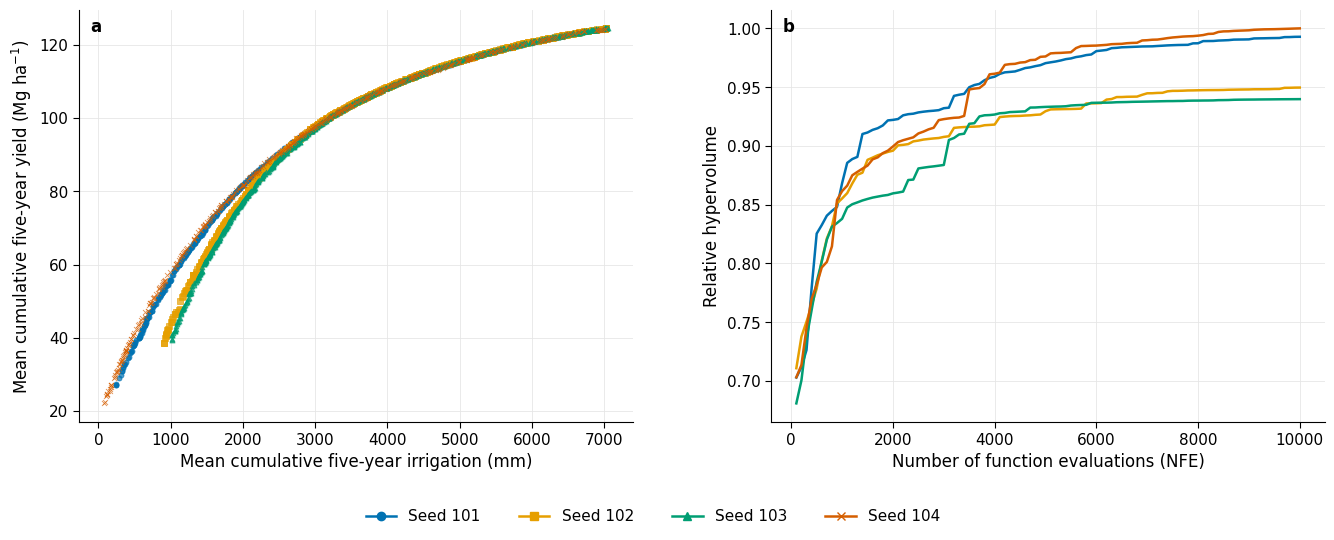

In [3]:
# Figure S15: Convergence across independent NSGA-II runs

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from pymoo.indicators.hv import HV
from pymoo.util.nds.non_dominated_sorting import NonDominatedSorting

base_dir = Path("NSGA2_K300_P100_G100_MultiSeeds")
run_dirs = {
    101: Path("NSGA2_K300_P100_G100_S101"),
    102: base_dir / "seed_102",
    103: base_dir / "seed_103",
    104: base_dir / "seed_104",
}
population_size = 100

def load_objectives(path):
    df = pd.read_csv(path)
    for col in ["irr_mean", "yld_mean"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    return df.dropna(subset=["irr_mean", "yld_mean"])

def get_nondominated(df):
    df = df.drop_duplicates(subset=["irr_mean", "yld_mean"])
    F = np.column_stack([df["irr_mean"], -df["yld_mean"]])
    idx = NonDominatedSorting().do(F, only_non_dominated_front=True)
    return df.iloc[idx].sort_values("irr_mean").reset_index(drop=True)

archives = {
    seed: load_objectives(directory / "final_pareto_archive_from_all_population.csv")
    for seed, directory in run_dirs.items()
}

all_archives = pd.concat(archives.values(), ignore_index=True)
combined_F = np.column_stack([all_archives["irr_mean"], -all_archives["yld_mean"]])

fmin = combined_F.min(axis=0)
fmax = combined_F.max(axis=0)
reference_point = fmax + 0.05 * (fmax - fmin)
hv_indicator = HV(ref_point=reference_point)

def calculate_hv(df):
    front = get_nondominated(df)
    F = np.column_stack([front["irr_mean"], -front["yld_mean"]])
    return float(hv_indicator(F))

final_hv = {seed: calculate_hv(df) for seed, df in archives.items()}
best_hv = max(final_hv.values())

summary = pd.DataFrame([
    {
        "Seed": seed,
        "Archive size": len(df),
        "Unique nondominated points": len(get_nondominated(df)),
        "Min irrigation (mm)": df["irr_mean"].min(),
        "Max irrigation (mm)": df["irr_mean"].max(),
        "Min yield (Mg/ha)": df["yld_mean"].min(),
        "Max yield (Mg/ha)": df["yld_mean"].max(),
        "Final hypervolume": final_hv[seed],
        "Relative hypervolume": final_hv[seed] / best_hv,
    }
    for seed, df in archives.items()
])

print("\nINDEPENDENT NSGA-II RUN COMPARISON")
print("=" * 80)
print(summary.round(4).to_string(index=False))

print("\nCOMMON HYPERVOLUME REFERENCE POINT")
print(f"Irrigation: {reference_point[0]:.4f} mm")
print(f"Negative yield: {reference_point[1]:.4f} Mg ha^-1")

print("\nFINAL RELATIVE HYPERVOLUME")
for seed in run_dirs:
    print(f"Seed {seed}: {final_hv[seed] / best_hv:.4f}")

# Hypervolume progression
hv_progress = {}

for seed, directory in run_dirs.items():
    population_files = sorted((directory / "population_by_generation").glob("*.csv"))
    if not population_files:
        raise FileNotFoundError(f"No population CSV files in {directory / 'population_by_generation'}")

    cumulative, records = [], []

    for generation, path in enumerate(population_files, start=1):
        pop = load_objectives(path)

        if {"G1", "G2"}.issubset(pop.columns):
            pop = pop[(pop["G1"] <= 0) & (pop["G2"] <= 0)]

        cumulative.append(pop)
        combined = pd.concat(cumulative, ignore_index=True)

        records.append({
            "generation": generation,
            "NFE": generation * population_size,
            "HV": calculate_hv(combined),
        })

    hv_progress[seed] = pd.DataFrame(records)
    hv_progress[seed]["Relative HV"] = hv_progress[seed]["HV"] / best_hv

print("\nHYPERVOLUME CONVERGENCE")
for seed, d in hv_progress.items():
    print(
        f"Seed {seed}: Final NFE = {d['NFE'].iloc[-1]:,}, "
        f"Final relative HV = {d['Relative HV'].iloc[-1]:.4f}"
    )

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 11,
    "axes.labelsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "axes.linewidth": 0.8,
})

colors = {
    101: "#0072B2",
    102: "#E69F00",
    103: "#009E73",
    104: "#D55E00",
}
markers = {101: "o", 102: "s", 103: "^", 104: "x"}

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharex=False)

# (a) Pareto-front comparison
for seed, df in archives.items():
    front = get_nondominated(df)
    axes[0].scatter(
        front["irr_mean"], front["yld_mean"],
        s=13, marker=markers[seed], color=colors[seed],
        alpha=0.7, linewidths=0.6,
    )

axes[0].set_xlabel("Mean cumulative five-year irrigation (mm)")
axes[0].set_ylabel("Mean cumulative five-year yield (Mg ha$^{-1}$)")

# (b) Hypervolume convergence
for seed, d in hv_progress.items():
    axes[1].plot(
        d["NFE"], d["Relative HV"],
        color=colors[seed], linewidth=1.8,
    )

axes[1].set_xlabel("Number of function evaluations (NFE)")
axes[1].set_ylabel("Relative hypervolume")

for ax, letter in zip(axes, ["a", "b"]):
    ax.text(
        0.02, 0.98, letter, transform=ax.transAxes,
        fontsize=12, fontweight="bold", va="top", ha="left",
    )
    ax.grid(color="0.9", linewidth=0.6)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(direction="out", length=4)

legend_handles = [
    Line2D(
        [0], [0], color=colors[seed], marker=markers[seed],
        linestyle="-", linewidth=1.8, markersize=6,
        label=f"Seed {seed}",
    )
    for seed in run_dirs
]

fig.legend(
    handles=legend_handles,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.01),
    ncol=4,
    frameon=False,
    columnspacing=2.5,
    handlelength=2.0,
)

fig.subplots_adjust(
    left=0.09, right=0.98,
    bottom=0.22, top=0.97, wspace=0.25,
)

plt.show()


PARETO-FRONT STABILITY ACROSS SOW ENSEMBLE SIZES
   K  Pareto solutions  Minimum irrigation (mm)  Maximum irrigation (mm)  Minimum yield (Mg/ha)  Maximum yield (Mg/ha)  Attainable yield <= 2000 mm  Interpolated yield at 2000 mm  Attainable yield change from K=300 (%)  Interpolated yield change from K=300 (%)
 300               558                 243.5737                7008.6696                27.0292               124.4738                      81.7124                        81.7628                                  0.0000                                    0.0000
 700               483                 131.0793                7004.5083                22.9013               124.0321                      81.4420                        81.4671                                 -0.3309                                   -0.3617
1000               496                 167.1961                6934.3634                23.4788               124.0661                      81.3542                    

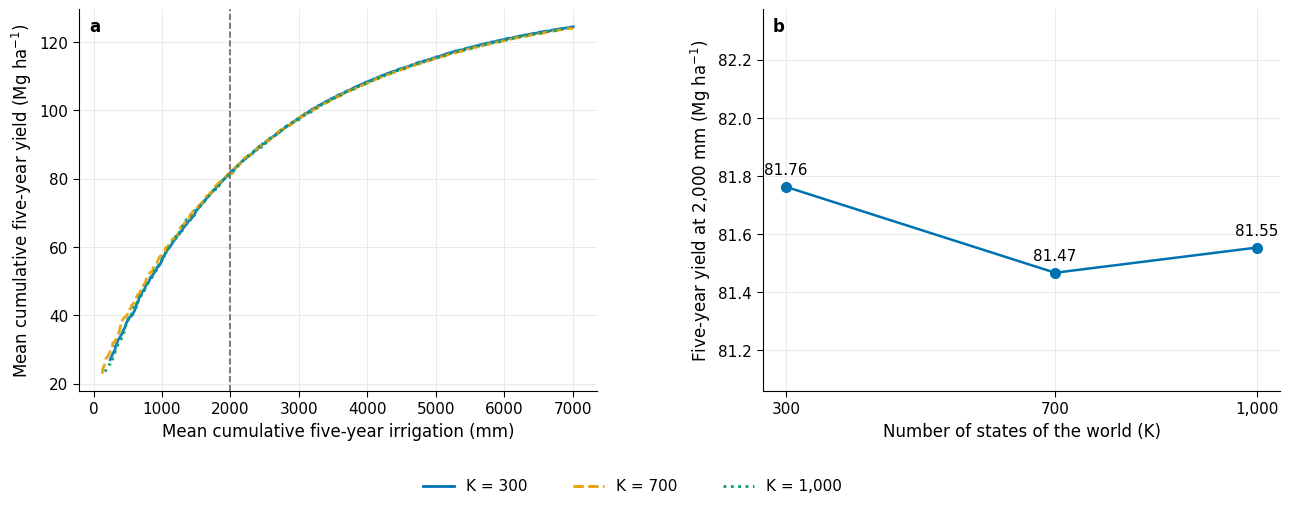

In [4]:
# Figure S16: Pareto-front stability across SOW ensemble sizes

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from pymoo.util.nds.non_dominated_sorting import NonDominatedSorting

run_dirs = {
    300: Path("NSGA2_K300_P100_G100_S101"),
    700: Path("NSGA2_K700_P100_G100_S101_Reoptimization"),
    1000: Path("NSGA2_K1000_P100_G100_S101_Reoptimization"),
}

IRRIGATION_TARGET = 2000.0

def load_front(directory):
    df = pd.read_csv(directory / "final_pareto_archive_from_all_population.csv")

    for col in ["irr_mean", "yld_mean"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    df = df.dropna(subset=["irr_mean", "yld_mean"])

    if "feasible" in df.columns:
        df = df[df["feasible"].astype(str).str.lower().eq("true")]

    df = df.drop_duplicates(subset=["irr_mean", "yld_mean"])
    F = np.column_stack([df["irr_mean"], -df["yld_mean"]])
    idx = NonDominatedSorting().do(F, only_non_dominated_front=True)

    return df.iloc[idx].sort_values("irr_mean").reset_index(drop=True)

fronts = {K: load_front(directory) for K, directory in run_dirs.items()}

def attainable_yield(front, target):
    eligible = front[front["irr_mean"] <= target]
    return eligible["yld_mean"].max() if not eligible.empty else np.nan

def interpolated_yield(front, target):
    x = front["irr_mean"].to_numpy()
    y = front["yld_mean"].to_numpy()

    if target < x.min() or target > x.max():
        return np.nan

    return float(np.interp(target, x, y))

results = pd.DataFrame([
    {
        "K": K,
        "Pareto solutions": len(front),
        "Minimum irrigation (mm)": front["irr_mean"].min(),
        "Maximum irrigation (mm)": front["irr_mean"].max(),
        "Minimum yield (Mg/ha)": front["yld_mean"].min(),
        "Maximum yield (Mg/ha)": front["yld_mean"].max(),
        "Attainable yield <= 2000 mm": attainable_yield(front, IRRIGATION_TARGET),
        "Interpolated yield at 2000 mm": interpolated_yield(front, IRRIGATION_TARGET),
    }
    for K, front in fronts.items()
]).sort_values("K").reset_index(drop=True)

for metric in ["Attainable", "Interpolated"]:
    column = f"{metric} yield {'<= ' if metric == 'Attainable' else 'at '}2000 mm"
    baseline = results.loc[results["K"] == 300, column].iloc[0]
    results[f"{metric} yield change from K=300 (%)"] = (
        (results[column] - baseline) / abs(baseline) * 100
    )

print("\nPARETO-FRONT STABILITY ACROSS SOW ENSEMBLE SIZES")
print("=" * 85)
print(results.round(4).to_string(index=False))

print("\nMAXIMUM ABSOLUTE CHANGE FROM K = 300")
for metric in ["Interpolated", "Attainable"]:
    change = results[f"{metric} yield change from K=300 (%)"].abs().max()
    print(f"{metric} yield: {change:.3f}%")

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 11,
    "axes.labelsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "axes.linewidth": 0.8,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

colors = {300: "#0072B2", 700: "#E69F00", 1000: "#009E73"}
linestyles = {300: "-", 700: "--", 1000: ":"}

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.3))

# (a) Pareto-front comparison
ax = axes[0]

for K, front in fronts.items():
    ax.plot(
        front["irr_mean"], front["yld_mean"],
        color=colors[K], linestyle=linestyles[K],
        linewidth=2.0, alpha=0.9, label=f"K = {K:,}"
    )

ax.axvline(IRRIGATION_TARGET, color="0.4", linestyle="--", linewidth=1.2)
ax.set_xlabel("Mean cumulative five-year irrigation (mm)")
ax.set_ylabel("Mean cumulative five-year yield (Mg ha$^{-1}$)")

# (b) Yield at fixed irrigation
ax = axes[1]

x_values = results["K"].to_numpy()
y_values = results["Interpolated yield at 2000 mm"].to_numpy()

ax.plot(
    x_values, y_values,
    color="#0072B2", linewidth=1.8, marker="o", markersize=7
)

ax.set_xticks(x_values)
ax.set_xticklabels([f"{K:,}" for K in x_values])
ax.set_xlabel("Number of states of the world (K)")
ax.set_ylabel("Five-year yield at 2,000 mm (Mg ha$^{-1}$)")

for x, y in zip(x_values, y_values):
    if np.isfinite(y):
        ax.annotate(
            f"{y:.2f}", (x, y), xytext=(0, 9),
            textcoords="offset points", ha="center", fontsize=11
        )

for ax, letter in zip(axes, ["a", "b"]):
    ax.text(
        0.02, 0.98, letter, transform=ax.transAxes,
        fontsize=12, fontweight="bold", va="top", ha="left"
    )
    ax.grid(color="0.9", linewidth=0.6)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(direction="out", length=4)

finite_y = y_values[np.isfinite(y_values)]

if len(finite_y):
    ymin, ymax = finite_y.min(), finite_y.max()
    padding = max((ymax - ymin) * 0.35, abs(ymin) * 0.005)
    axes[1].set_ylim(ymin - padding, ymax + padding * 1.5)

handles = [
    Line2D(
        [0], [0], color=colors[K], linestyle=linestyles[K],
        linewidth=2, label=f"K = {K:,}"
    )
    for K in run_dirs
]

fig.legend(
    handles=handles, loc="lower center",
    bbox_to_anchor=(0.5, 0.01), ncol=3,
    frameon=False, columnspacing=3
)

fig.subplots_adjust(
    left=0.09, right=0.98,
    bottom=0.23, top=0.95, wspace=0.32
)

plt.show()

Decision levers plotted: ['planting_doy', 'yield_cutoff', 'establishment_days', 'MAD', 'refill_target', 'survival_fraction', 'max_irrigation', 'initial_smt', 'min_infiltration', 'pre_harvest_no_irrigation_days', 'post_cutting_buffer_days', 'DI_establishment', 'DI_winter', 'DI_spring', 'DI_summer', 'DI_fall']


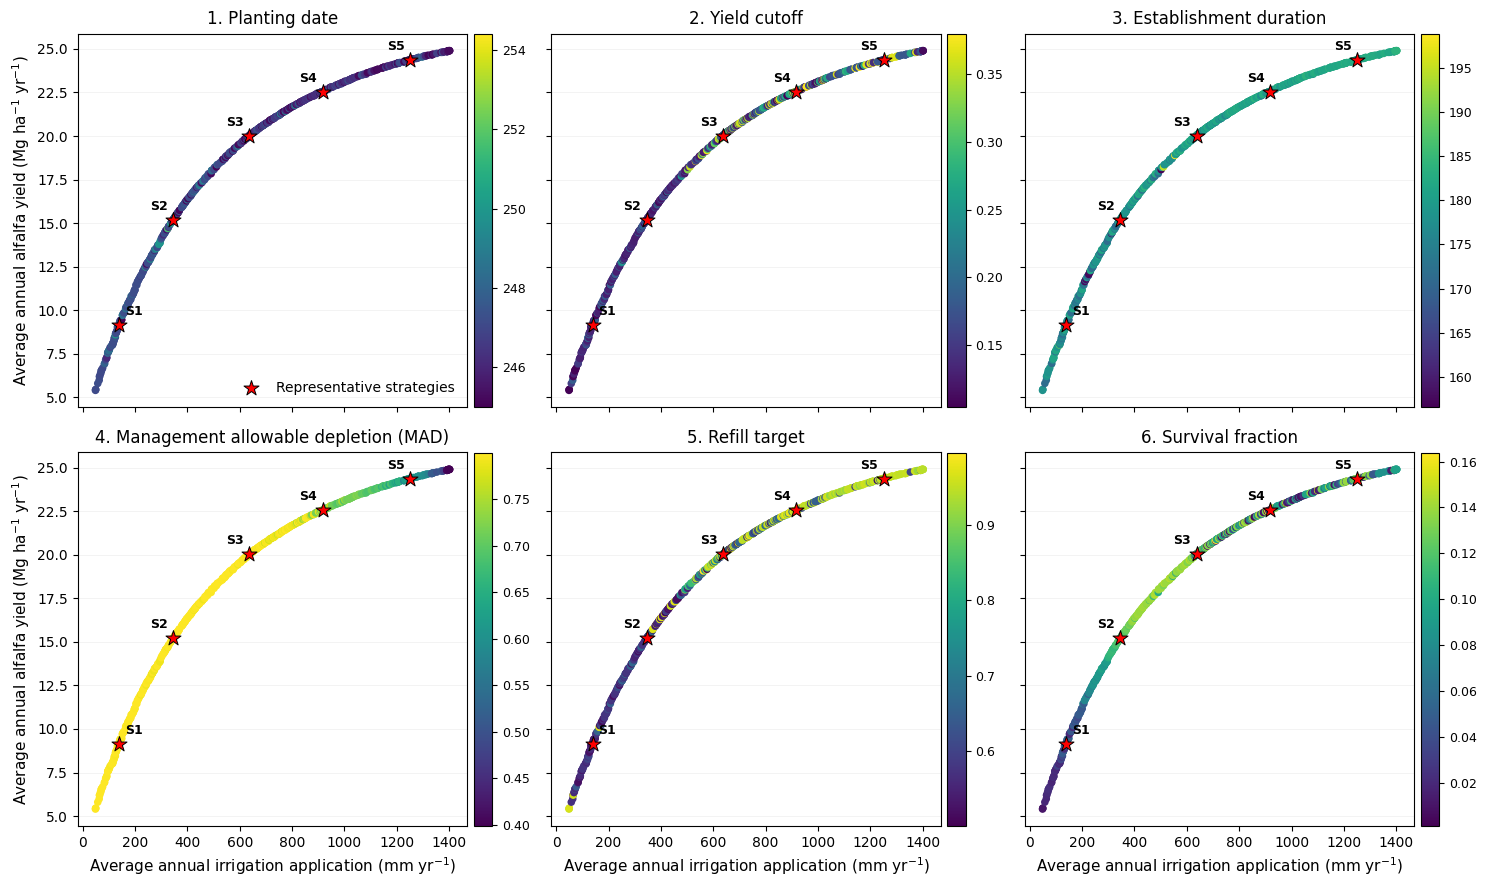

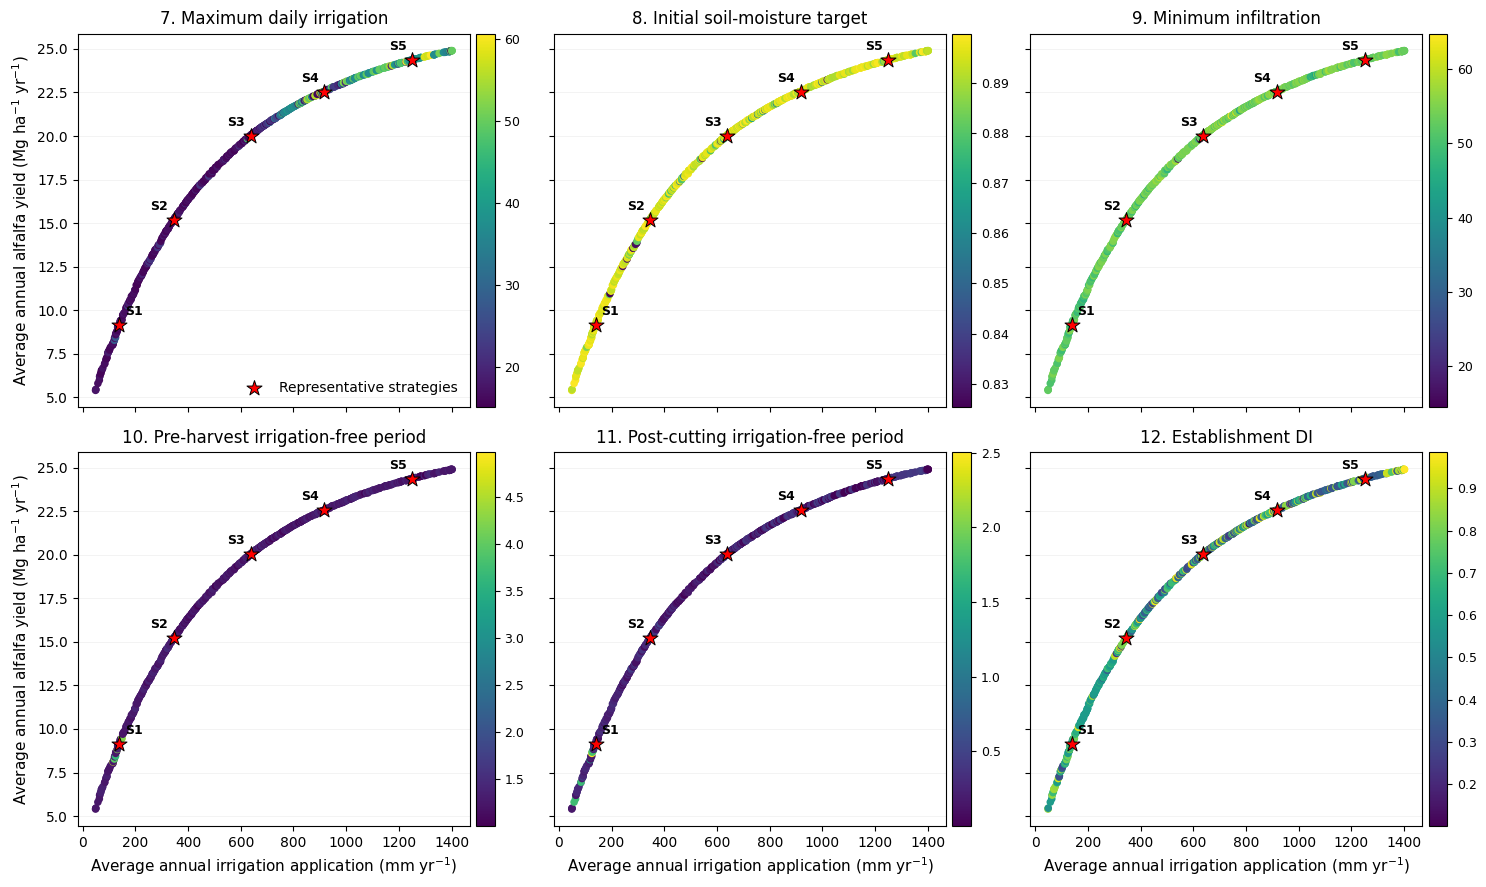

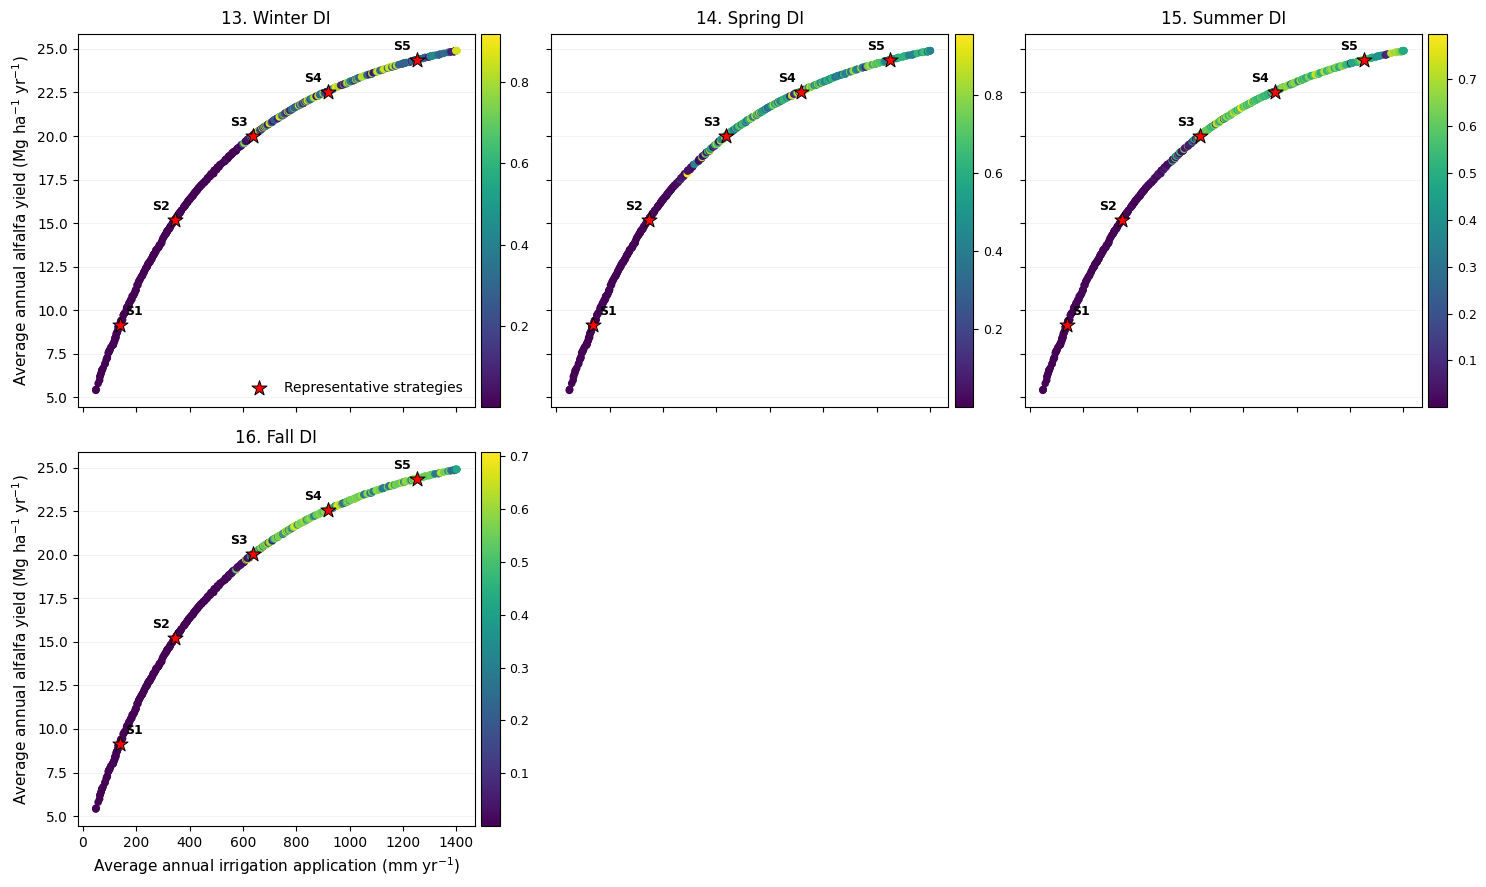

In [5]:
# Figure S17: Decision-lever values across the cumulative Pareto front

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

df = pd.read_csv(
    "NSGA2_K300_P100_G100_S101/final_pareto_archive_from_all_population.csv"
)
selected_df = pd.read_csv(
    "Strategies_Performance/selected_5_representative_strategies.csv"
)

for data in [df, selected_df]:
    data["irr_annual"] = data["irr_mean"] / 5
    data["yld_annual"] = data["yld_mean"] / 5

df = df.sort_values("irr_annual")
strategy_order = ["S1", "S2", "S3", "S4", "S5"]
selected_df = selected_df[selected_df["strategy_id"].isin(strategy_order)].copy()
selected_df["strategy_id"] = pd.Categorical(
    selected_df["strategy_id"], categories=strategy_order, ordered=True
)
selected_df = selected_df.sort_values("strategy_id").reset_index(drop=True)

decision_levers = [
    "planting_doy", "yield_cutoff", "establishment_days", "MAD",
    "refill_target", "survival_fraction", "max_irrigation", "initial_smt",
    "min_infiltration", "pre_harvest_no_irrigation_days",
    "post_cutting_buffer_days", "DI_establishment", "DI_winter",
    "DI_spring", "DI_summer", "DI_fall",
]

pretty_names = {
    "planting_doy": "Planting date",
    "yield_cutoff": "Yield cutoff",
    "establishment_days": "Establishment duration",
    "MAD": "Management allowable depletion (MAD)",
    "refill_target": "Refill target",
    "survival_fraction": "Survival fraction",
    "max_irrigation": "Maximum daily irrigation",
    "initial_smt": "Initial soil-moisture target",
    "min_infiltration": "Minimum infiltration",
    "pre_harvest_no_irrigation_days": "Pre-harvest irrigation-free period",
    "post_cutting_buffer_days": "Post-cutting irrigation-free period",
    "DI_establishment": "Establishment DI",
    "DI_winter": "Winter DI",
    "DI_spring": "Spring DI",
    "DI_summer": "Summer DI",
    "DI_fall": "Fall DI",
}

decision_levers = [var for var in decision_levers if var in df.columns]
print("Decision levers plotted:", decision_levers)

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 11,
    "axes.labelsize": 11,
    "axes.titlesize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "axes.linewidth": 0.8,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
})

for start in range(0, len(decision_levers), 6):
    vars_group = decision_levers[start:start + 6]
    fig, axes = plt.subplots(2, 3, figsize=(15, 9), sharex=True, sharey=True)
    axes = axes.flatten()

    for ax, var in zip(axes, vars_group):
        sc = ax.scatter(
            df["irr_annual"], df["yld_annual"],
            c=df[var], cmap="viridis", s=30,
            edgecolors="none", zorder=2
        )

        ax.scatter(
            selected_df["irr_annual"], selected_df["yld_annual"],
            marker="*", s=130, color="red", edgecolor="black",
            linewidth=0.7, zorder=5, label="Representative strategies"
        )

        for _, row in selected_df.iterrows():
            sid = str(row["strategy_id"])
            ax.annotate(
                sid, (row["irr_annual"], row["yld_annual"]),
                xytext=(4, 5) if sid == "S1" else (-4, 5),
                textcoords="offset points", fontsize=9,
                fontweight="bold", ha="left" if sid == "S1" else "right",
                va="bottom", zorder=6
            )

        ax.set_title(
            f"{decision_levers.index(var) + 1}. {pretty_names.get(var, var)}",
            pad=7
        )
        ax.grid(axis="y", linewidth=0.5, alpha=0.20)
        ax.grid(axis="x", visible=False)

        for spine in ax.spines.values():
            spine.set_visible(True)
            spine.set_linewidth(0.8)

        ax.tick_params(direction="out", top=False, right=False)
        cbar = fig.colorbar(sc, ax=ax, pad=0.015, fraction=0.045)
        cbar.ax.tick_params(labelsize=9)

    for i, ax in enumerate(axes):
        if i % 3 == 0:
            ax.set_ylabel(r"Average annual alfalfa yield (Mg ha$^{-1}$ yr$^{-1}$)")
        if i // 3 == 1:
            ax.set_xlabel(r"Average annual irrigation application (mm yr$^{-1}$)")

    for ax in axes[len(vars_group):]:
        ax.axis("off")

    axes[0].legend(frameon=False, loc="lower right")

    fig.tight_layout()
    plt.show()


Decision-variable variation:
                         Display_name  Archive_fraction_of_search_space  Selected_fraction_of_search_space
                           Spring DI                             0.956                              0.921
                       Refill target                             0.989                              0.875
                           Summer DI                             0.797                              0.712
                             Fall DI                             0.708                              0.628
                    Establishment DI                             0.883                              0.570
                   Survival fraction                             0.542                              0.411
Management allowable depletion (MAD)                             0.668                              0.328
                           Winter DI                             0.918                              0.252
            Max

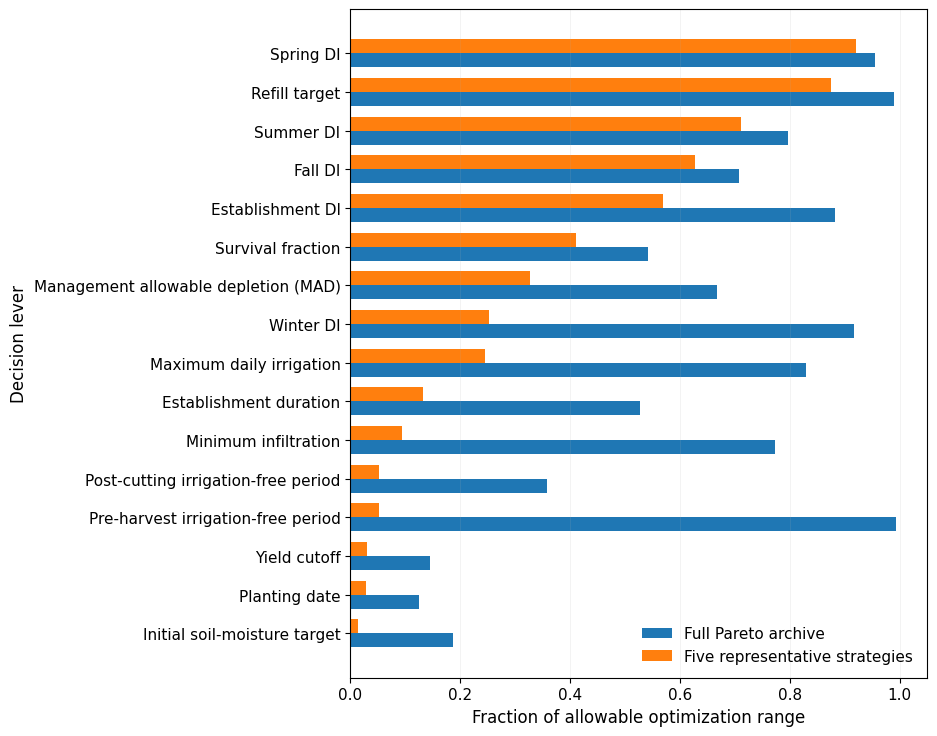

In [6]:
# Figure S18: Decision-variable variation across the Pareto archive

import pandas as pd
import matplotlib.pyplot as plt

archive = pd.read_csv(
    "NSGA2_K300_P100_G100_S101/final_pareto_archive_from_all_population.csv"
)
selected = pd.read_csv(
    "Strategies_Performance/selected_5_representative_strategies.csv"
)

bounds = {
    "planting_doy": (245, 320),
    "yield_cutoff": (0.10, 2.00),
    "establishment_days": (120, 200),
    "MAD": (0.20, 0.80),
    "refill_target": (0.50, 1.00),
    "survival_fraction": (0.00, 0.30),
    "max_irrigation": (15.0, 70.0),
    "initial_smt": (0.50, 0.90),
    "min_infiltration": (5.0, 70.0),
    "pre_harvest_no_irrigation_days": (1, 5),
    "post_cutting_buffer_days": (0, 7),
    "DI_establishment": (0.0, 1.0),
    "DI_winter": (0.0, 1.0),
    "DI_spring": (0.0, 1.0),
    "DI_summer": (0.0, 1.0),
    "DI_fall": (0.0, 1.0),
}

pretty_names = {
    "planting_doy": "Planting date",
    "yield_cutoff": "Yield cutoff",
    "establishment_days": "Establishment duration",
    "MAD": "Management allowable depletion (MAD)",
    "refill_target": "Refill target",
    "survival_fraction": "Survival fraction",
    "max_irrigation": "Maximum daily irrigation",
    "initial_smt": "Initial soil-moisture target",
    "min_infiltration": "Minimum infiltration",
    "pre_harvest_no_irrigation_days": "Pre-harvest irrigation-free period",
    "post_cutting_buffer_days": "Post-cutting irrigation-free period",
    "DI_establishment": "Establishment DI",
    "DI_winter": "Winter DI",
    "DI_spring": "Spring DI",
    "DI_summer": "Summer DI",
    "DI_fall": "Fall DI",
}

decision_variables = list(bounds)

for name, data in [("Pareto archive", archive), ("representative strategies", selected)]:
    missing = [var for var in decision_variables if var not in data.columns]
    if missing:
        raise ValueError(f"Missing decision variables in {name}: {missing}")

rows = []

for var, (lower, upper) in bounds.items():
    archive_min, archive_max = archive[var].min(), archive[var].max()
    selected_min, selected_max = selected[var].min(), selected[var].max()

    rows.append({
        "Decision_variable": var,
        "Display_name": pretty_names[var],
        "Lower_bound": lower,
        "Upper_bound": upper,
        "Archive_min": archive_min,
        "Archive_max": archive_max,
        "Selected_min": selected_min,
        "Selected_max": selected_max,
        "Archive_fraction_of_search_space": (archive_max - archive_min) / (upper - lower),
        "Selected_fraction_of_search_space": (selected_max - selected_min) / (upper - lower),
    })

summary = pd.DataFrame(rows).sort_values(
    "Selected_fraction_of_search_space", ascending=False
).reset_index(drop=True)

summary["Selected_rank"] = (
    summary["Selected_fraction_of_search_space"]
    .rank(method="min", ascending=False).astype(int)
)

print(
    "\nDecision-variable variation:\n",
    summary[
        ["Display_name", "Archive_fraction_of_search_space",
         "Selected_fraction_of_search_space"]
    ].round(3).to_string(index=False)
)

plot_data = summary.iloc[::-1]

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 11,
    "axes.labelsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "axes.linewidth": 0.8,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
})

fig, ax = plt.subplots(figsize=(9.5, 7.5))

y_positions = list(range(len(plot_data)))
bar_height = 0.36

ax.barh(
    [y - bar_height / 2 for y in y_positions],
    plot_data["Archive_fraction_of_search_space"],
    height=bar_height,
    label="Full Pareto archive"
)

ax.barh(
    [y + bar_height / 2 for y in y_positions],
    plot_data["Selected_fraction_of_search_space"],
    height=bar_height,
    label="Five representative strategies"
)

ax.set_yticks(y_positions)
ax.set_yticklabels(plot_data["Display_name"])
ax.set_xlim(0, 1.05)
ax.set_xlabel("Fraction of allowable optimization range")
ax.set_ylabel("Decision lever")

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(0.8)

ax.grid(axis="x", linewidth=0.5, alpha=0.20)
ax.grid(axis="y", visible=False)
ax.tick_params(direction="out", top=False, right=False)
ax.legend(frameon=False, loc="lower right")

plt.tight_layout()
plt.show()

In [7]:
# Table S11: Robustness stability across SOW ensemble sizes

from pathlib import Path
import pandas as pd

input_folder = Path("Strategies_Performance")
SEED = 54321

BASELINE_IRR = 5834.781
BASELINE_YLD = 105.978
IRR_THRESHOLD = 0.80 * BASELINE_IRR
YLD_THRESHOLD = 0.80 * BASELINE_YLD

files = {
    K: input_folder / f"K{K}" /
    f"strategy_performance_across_futures_k{K}_seed{SEED}.csv"
    for K in [10000, 50000]
}

required = [
    "strategy_id", "strategy_label", "future_id",
    "cumulative_irrigation_mm", "cumulative_yield_Mg_ha"
]

results = []

for K, file in files.items():
    df = pd.read_csv(file)

    missing = set(required) - set(df.columns)
    if missing:
        raise ValueError(f"{file.name}: missing columns {sorted(missing)}")

    if df[required].isna().any().any():
        raise ValueError(f"{file.name}: missing required values")

    if df.duplicated(["strategy_id", "future_id"]).any():
        raise ValueError(f"{file.name}: duplicate strategy-future pairs")

    if "status" in df.columns and not df["status"].eq("success").all():
        raise ValueError(f"{file.name}: unsuccessful simulations found")

    if df["strategy_id"].nunique() != 5:
        raise ValueError(f"{file.name}: expected five strategies")

    if not df.groupby("strategy_id")["future_id"].nunique().eq(K).all():
        raise ValueError(f"{file.name}: expected {K} SOWs per strategy")

    if not df.groupby("strategy_id")["strategy_label"].nunique().eq(1).all():
        raise ValueError(f"{file.name}: inconsistent strategy labels")

    df["joint_success"] = (
        (df["cumulative_irrigation_mm"] <= IRR_THRESHOLD)
        & (df["cumulative_yield_Mg_ha"] >= YLD_THRESHOLD)
    )

    robustness = df.groupby(["strategy_id", "strategy_label"])["joint_success"].mean()

    for (sid, label), value in robustness.items():
        results.append({
            "strategy_id": sid,
            "Strategy": label,
            "K": K,
            "Robustness (%)": 100 * value
        })

results = pd.DataFrame(results)

a = results[results["K"] == 10000].set_index("strategy_id")
b = results[results["K"] == 50000].set_index("strategy_id")

if not a["Strategy"].sort_index().equals(b["Strategy"].sort_index()):
    raise ValueError("Strategy labels differ between datasets")

comparison = pd.DataFrame({
    "Strategy": a["Strategy"],
    "Robustness K=10000 (%)": a["Robustness (%)"],
    "Robustness K=50000 (%)": b["Robustness (%)"]
})

comparison["Absolute difference (pp)"] = (
    comparison["Robustness K=50000 (%)"]
    - comparison["Robustness K=10000 (%)"]
).abs()

comparison = comparison.sort_values("Strategy")

print("\nTABLE S11. STABILITY OF JOINT ROBUSTNESS ESTIMATES")
print("=" * 80)

table_s11 = comparison.reset_index(drop=True)

print(table_s11.to_string(
    index=False,
    formatters={
        "Robustness K=10000 (%)": "{:.3f}".format,
        "Robustness K=50000 (%)": "{:.3f}".format,
        "Absolute difference (pp)": "{:.3f}".format
    }
))

max_diff = comparison["Absolute difference (pp)"].max()
mean_diff = comparison["Absolute difference (pp)"].mean()

rank_10k = comparison["Robustness K=10000 (%)"].rank(
    ascending=False, method="min"
)
rank_50k = comparison["Robustness K=50000 (%)"].rank(
    ascending=False, method="min"
)

print("\nSTABILITY SUMMARY")
print("=" * 70)
print(f"Maximum absolute difference: {max_diff:.3f} pp")
print(f"Mean absolute difference: {mean_diff:.3f} pp")
print(f"Strategy ranking unchanged: {(rank_10k == rank_50k).all()}")


TABLE S11. STABILITY OF JOINT ROBUSTNESS ESTIMATES
                   Strategy Robustness K=10000 (%) Robustness K=50000 (%) Absolute difference (pp)
          S1 Low irrigation                  0.150                  0.104                    0.046
 S2 Low-moderate irrigation                 29.640                 29.472                    0.168
       S3 Balanced strategy                 65.060                 64.580                    0.480
S4 Moderate-high production                 40.230                 40.320                    0.090
         S5 High production                  7.200                  7.464                    0.264

STABILITY SUMMARY
Maximum absolute difference: 0.480 pp
Mean absolute difference: 0.210 pp
Strategy ranking unchanged: True



FIGURE S19 — JOINT ROBUSTNESS (%)
             Yield loss ≤ 10%  Yield loss ≤ 20%  Yield loss ≤ 30%
strategy_id                                                      
S1                       0.00              0.15              1.48
S2                      15.24             29.64             49.43
S3                      48.23             65.06             79.56
S4                      29.81             40.23             48.69
S5                       4.79              7.20              9.82


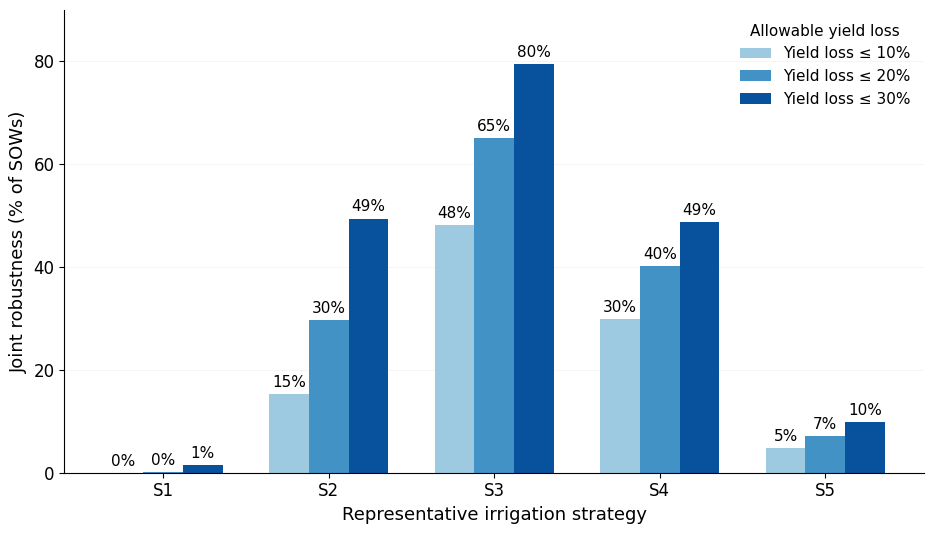

In [8]:
# Figure S19: Joint robustness under different yield-loss thresholds

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(
    "Strategies_Performance/K10000/"
    "strategy_performance_across_futures_k10000_seed54321.csv"
)
df = df[df["status"] == "success"].copy()

baseline_irr = 5834.781
baseline_yld = 105.978
strategy_order = ["S1", "S2", "S3", "S4", "S5"]
yield_losses = [0.10, 0.20, 0.30]

assert set(df["strategy_id"]) == set(strategy_order)
assert df.groupby("strategy_id")["future_id"].nunique().eq(10000).all()
assert df.groupby("strategy_id").size().eq(10000).all()

irr_ok = df["cumulative_irrigation_mm"] <= 0.80 * baseline_irr

results = {}

for loss in yield_losses:
    yld_ok = df["cumulative_yield_Mg_ha"] >= (1 - loss) * baseline_yld

    results[f"Yield loss ≤ {int(loss * 100)}%"] = (
        (irr_ok & yld_ok)
        .groupby(df["strategy_id"])
        .mean()
        .mul(100)
        .reindex(strategy_order)
    )

table = pd.DataFrame(results)

print("\nFIGURE S19 — JOINT ROBUSTNESS (%)")
print(table.round(3).to_string())

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 12,
    "axes.labelsize": 13,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 11,
    "axes.linewidth": 0.8,
})

fig, ax = plt.subplots(figsize=(9.5, 5.5))

x = np.arange(len(strategy_order))
width = 0.24
colors = ["#9ecae1", "#4292c6", "#08519c"]

for i, (column, color) in enumerate(zip(table.columns, colors)):
    values = table[column].to_numpy()
    bars = ax.bar(
        x + (i - 1) * width, values,
        width=width, color=color, label=column, edgecolor="none"
    )

    for bar, value in zip(bars, values):
        ax.annotate(
            f"{value:.0f}%",
            (bar.get_x() + bar.get_width() / 2, bar.get_height()),
            xytext=(0, 3), textcoords="offset points",
            ha="center", va="bottom", fontsize=11
        )

ax.set_xticks(x)
ax.set_xticklabels(strategy_order)
ax.set_ylabel("Joint robustness (% of SOWs)")
ax.set_xlabel("Representative irrigation strategy")
ax.set_ylim(0, 90)
ax.set_yticks(np.arange(0, 91, 20))

ax.legend(
    title="Allowable yield loss", frameon=False,
    loc="upper right", fontsize=11, title_fontsize=11
)

ax.grid(axis="y", alpha=0.15, linewidth=0.6)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()
plt.show()


TABLE S12 — SOBOL SENSITIVITY CONVERGENCE
Strategy        Output  Mean |ΔST| 512→1024  Mean |ΔST| 1024→2048  Max |ΔST| 1024→2048  Top-six ranking unchanged
      S1    Irrigation               0.0012                0.0006               0.0037                       True
      S1 Alfalfa yield               0.0006                0.0001               0.0006                       True
      S2    Irrigation               0.0018                0.0008               0.0048                       True
      S2 Alfalfa yield               0.0008                0.0003               0.0019                       True
      S3    Irrigation               0.0007                0.0004               0.0024                       True
      S3 Alfalfa yield               0.0003                0.0002               0.0020                       True
      S4    Irrigation               0.0008                0.0005               0.0036                       True
      S4 Alfalfa yield               0.0002  

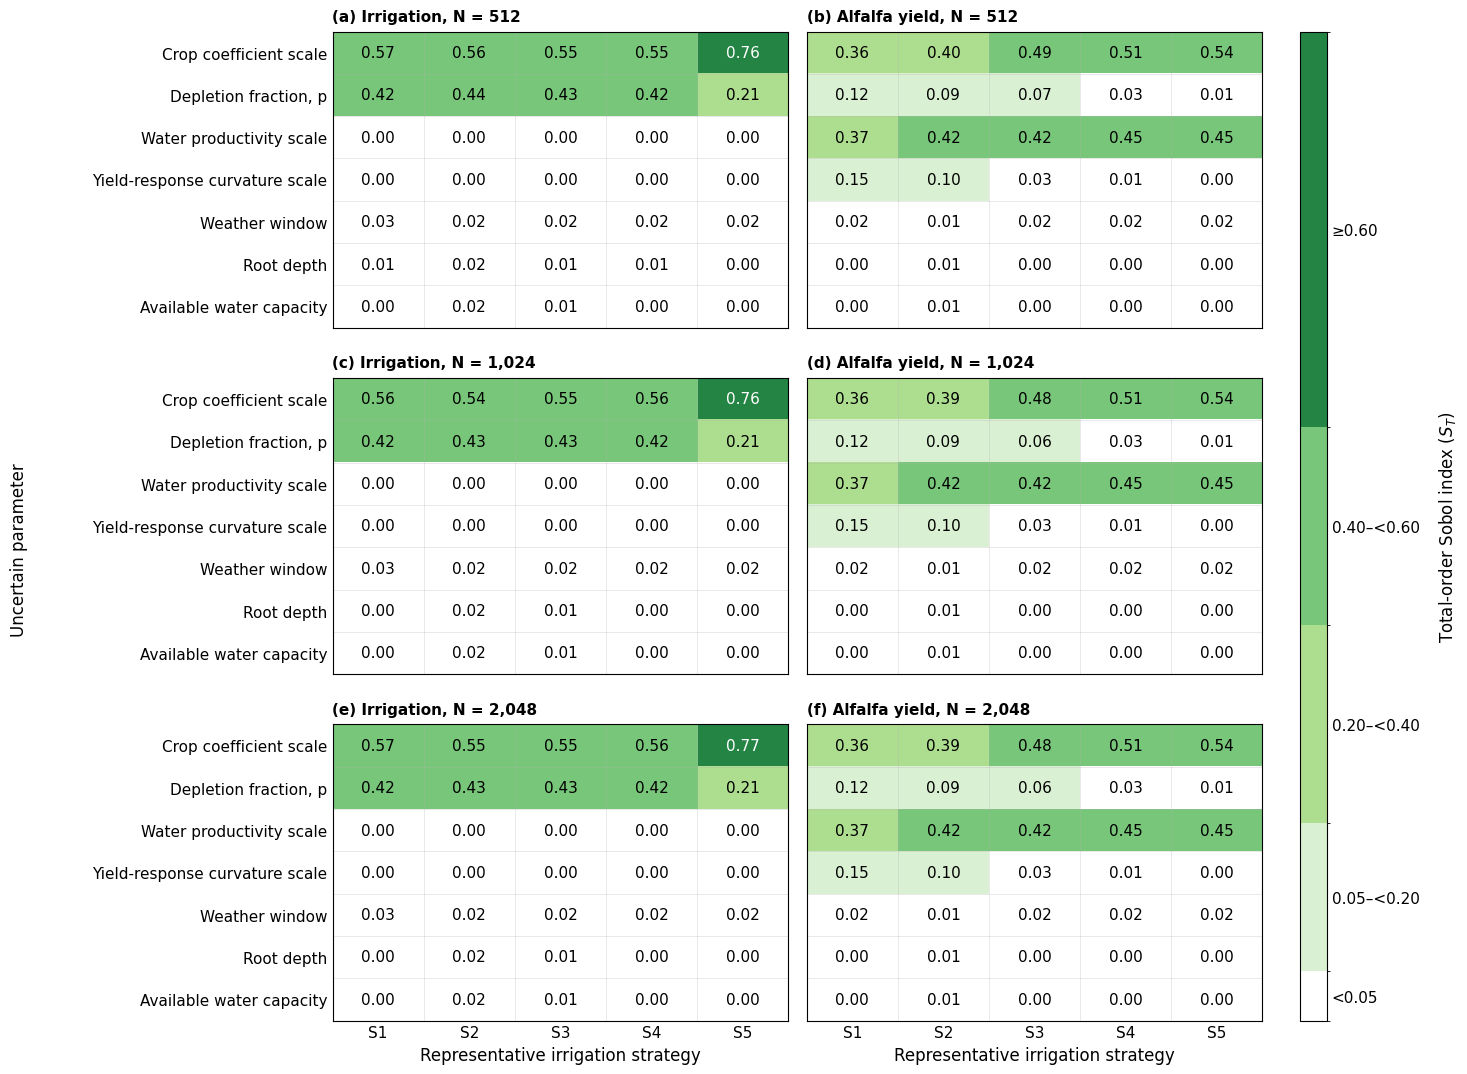

In [9]:
# Figure S20 and Table S12: Sobol sensitivity convergence

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm

SOBOL_DIR = Path("Sobol_Results")
SEED = 2026
N_VALUES = [512, 1024, 2048]
STRATEGIES = ["S1", "S2", "S3", "S4", "S5"]
OBJECTIVES = {"irr": "Irrigation", "yld": "Alfalfa yield"}

PARAMETER_LABELS = {
    "kc_scale": "Crop coefficient scale",
    "temperature_dormancy_threshold": "Dormancy temperature threshold",
    "p_depletion": "Depletion fraction, p",
    "wp_scale": "Water productivity scale",
    "Kmitsch_scale": "Yield-response curvature scale",
    "climate_window_u": "Weather window",
    "AWC_raw": "Available water capacity",
    "AWC": "Available water capacity",
    "root_depth_mm": "Root depth",
    "K_sat": "Saturated hydraulic conductivity",
    "theta_s_raw": "Saturated water content",
    "theta_s": "Saturated water content",
    "theta_r_raw": "Residual water content",
    "theta_r": "Residual water content",
    "n": "Van Genuchten n",
    "pwp_raw": "Permanent wilting point",
    "pwp": "Permanent wilting point",
}

def load_st(objective, n):
    series = {}

    for strategy in STRATEGIES:
        filename = f"sobol_Si_{strategy}_{objective}_N{n}_seed{SEED}.csv"
        candidates = [
            SOBOL_DIR / f"Sobol_{strategy}" / filename,
            SOBOL_DIR / f"N{n}" / f"Sobol_{strategy}" / filename,
            SOBOL_DIR / filename,
        ]

        path = next((p for p in candidates if p.is_file()), None)

        if path is None:
            matches = list(SOBOL_DIR.rglob(filename))
            if len(matches) != 1:
                raise FileNotFoundError(f"Expected one file for {filename}, found {len(matches)}")
            path = matches[0]

        df = pd.read_csv(path)

        if not {"param", "ST"}.issubset(df.columns):
            raise ValueError(f"Missing columns: {path}")
        if df["param"].duplicated().any():
            raise ValueError(f"Duplicate parameters: {path}")

        df["ST"] = pd.to_numeric(df["ST"], errors="raise")
        if not np.isfinite(df["ST"]).all():
            raise ValueError(f"Nonfinite ST estimates: {path}")

        series[strategy] = df.set_index("param")["ST"].astype(float)

    result = pd.DataFrame(series)

    if result.isna().any().any() or len(result) != 13:
        raise ValueError(f"Inconsistent parameters: {objective}, N={n}")

    return result

data = {
    objective: {n: load_st(objective, n) for n in N_VALUES}
    for objective in OBJECTIVES
}

for objective in OBJECTIVES:
    reference = set(data[objective][2048].index)
    for n in N_VALUES:
        if set(data[objective][n].index) != reference:
            raise ValueError(f"Parameter mismatch: {objective}, N={n}")

# Parameters displayed in Figure S20
mean_irr = data["irr"][2048][STRATEGIES].mean(axis=1)
mean_yld = data["yld"][2048][STRATEGIES].mean(axis=1)

top_irr = mean_irr.nlargest(5).index
top_yld = mean_yld.nlargest(5).index
common_parameters = list(dict.fromkeys(list(top_irr) + list(top_yld)))

combined_mean = (
    mean_irr.loc[common_parameters] + mean_yld.loc[common_parameters]
) / 2

common_parameters = combined_mean.sort_values(ascending=False).index.tolist()

# Table S12
rows = []

for strategy in STRATEGIES:
    for objective, label in OBJECTIVES.items():
        st512 = data[objective][512][strategy]
        st1024 = data[objective][1024][strategy]
        st2048 = data[objective][2048][strategy]

        delta1 = (st1024 - st512).abs()
        delta2 = (st2048 - st1024).abs()

        top1024 = st1024.nlargest(6).index.tolist()
        top2048 = st2048.nlargest(6).index.tolist()

        rows.append({
            "Strategy": strategy,
            "Output": label,
            "Mean |ΔST| 512→1024": delta1.mean(),
            "Mean |ΔST| 1024→2048": delta2.mean(),
            "Max |ΔST| 1024→2048": delta2.max(),
            "Top-six ranking unchanged": top1024 == top2048,
        })

table_s12 = pd.DataFrame(rows)

print("\nTABLE S12 — SOBOL SENSITIVITY CONVERGENCE")
print("=" * 105)
print(table_s12.round(4).to_string(index=False))

print("\nCONVERGENCE SUMMARY")
print(f"Mean |ΔST| 512→1024: {table_s12['Mean |ΔST| 512→1024'].mean():.4f}")
print(f"Mean |ΔST| 1024→2048: {table_s12['Mean |ΔST| 1024→2048'].mean():.4f}")
print(f"Maximum |ΔST| 1024→2048: {table_s12['Max |ΔST| 1024→2048'].max():.4f}")
print(
    f"Unchanged top-six rankings: "
    f"{table_s12['Top-six ranking unchanged'].sum()}/{len(table_s12)}"
)

# Figure S20
sensitivity_bounds = [0.00, 0.05, 0.20, 0.40, 0.60, 1.0001]
sensitivity_colors = ["white", "#d9f0d3", "#addd8e", "#78c679", "#238443"]

cmap = ListedColormap(sensitivity_colors)
cmap.set_under(sensitivity_colors[0])
cmap.set_over(sensitivity_colors[-1])
norm = BoundaryNorm(sensitivity_bounds, cmap.N)

colorbar_ticks = [0.025, 0.125, 0.30, 0.50, 0.80]
colorbar_labels = ["<0.05", "0.05–<0.20", "0.20–<0.40", "0.40–<0.60", "≥0.60"]

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 11,
    "axes.labelsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "axes.linewidth": 0.8,
})

fig, axes = plt.subplots(3, 2, figsize=(15, 11.5), sharex=True, sharey=True)

fig.subplots_adjust(
    left=0.24, right=0.86, bottom=0.09,
    top=0.95, wspace=0.04, hspace=0.17
)

for row, n in enumerate(N_VALUES):
    for col, (objective, label) in enumerate(OBJECTIVES.items()):
        ax = axes[row, col]
        matrix = data[objective][n].loc[common_parameters, STRATEGIES].to_numpy()

        image = ax.imshow(
            matrix, cmap=cmap, norm=norm,
            aspect="auto", interpolation="nearest"
        )

        ax.set_xticks(range(len(STRATEGIES)))
        ax.set_xticklabels(STRATEGIES)
        ax.set_yticks(range(len(common_parameters)))
        ax.set_yticklabels([
            PARAMETER_LABELS.get(p, p) for p in common_parameters
        ])

        panel = chr(ord("a") + row * 2 + col)
        ax.text(
            0, 1.025, f"({panel}) {label}, N = {n:,}",
            transform=ax.transAxes, fontsize=11,
            fontweight="bold", ha="left", va="bottom", clip_on=False
        )

        for i in range(len(common_parameters)):
            for j in range(len(STRATEGIES)):
                value = matrix[i, j]
                ax.text(
                    j, i, f"{value:.2f}",
                    ha="center", va="center", fontsize=11,
                    color="white" if value >= 0.60 else "black"
                )

        ax.set_xticks(np.arange(-0.5, len(STRATEGIES), 1), minor=True)
        ax.set_yticks(np.arange(-0.5, len(common_parameters), 1), minor=True)
        ax.grid(which="minor", color="0.70", linewidth=0.45, alpha=0.45)
        ax.tick_params(which="minor", bottom=False, left=False)
        ax.tick_params(which="major", length=0)

        ax.tick_params(axis="y", labelleft=(col == 0), left=(col == 0))
        ax.tick_params(axis="x", labelbottom=(row == len(N_VALUES) - 1))

        if row == len(N_VALUES) - 1:
            ax.set_xlabel("Representative irrigation strategy")

fig.supylabel("Uncertain parameter", fontsize=12, x=0.025)

cbar_ax = fig.add_axes([0.885, 0.09, 0.018, 0.86])
cbar = fig.colorbar(
    image, cax=cbar_ax, boundaries=sensitivity_bounds,
    ticks=colorbar_ticks, spacing="proportional"
)
cbar.ax.set_yticklabels(colorbar_labels, fontsize=11)
cbar.set_label(r"Total-order Sobol index ($S_T$)", fontsize=12, labelpad=12)
cbar.ax.tick_params(length=0)

plt.show()


TABLE S13 — PRIM CANDIDATE BOX COMPARISON
 Box  Dimensions  Density  Coverage  Mass                                                                                                           Restricted parameter ranges
  33           2    0.910     0.478 0.183                                                                      Crop coefficient scale ≤ 0.936; Water productivity scale ≤ 0.978
  34           3    0.921     0.459 0.174                                       Crop coefficient scale ≤ 0.936; Depletion fraction, p ≤ 0.647; Water productivity scale ≤ 0.978
  43           3    0.986     0.309 0.110                                       Crop coefficient scale ≤ 0.911; Depletion fraction, p ≤ 0.624; Water productivity scale ≤ 0.916
  44           4    0.993     0.282 0.099 Crop coefficient scale ≤ 0.911; Depletion fraction, p ≤ 0.624; Water productivity scale ≤ 0.916; Climate-window start year ≤ 2017.500


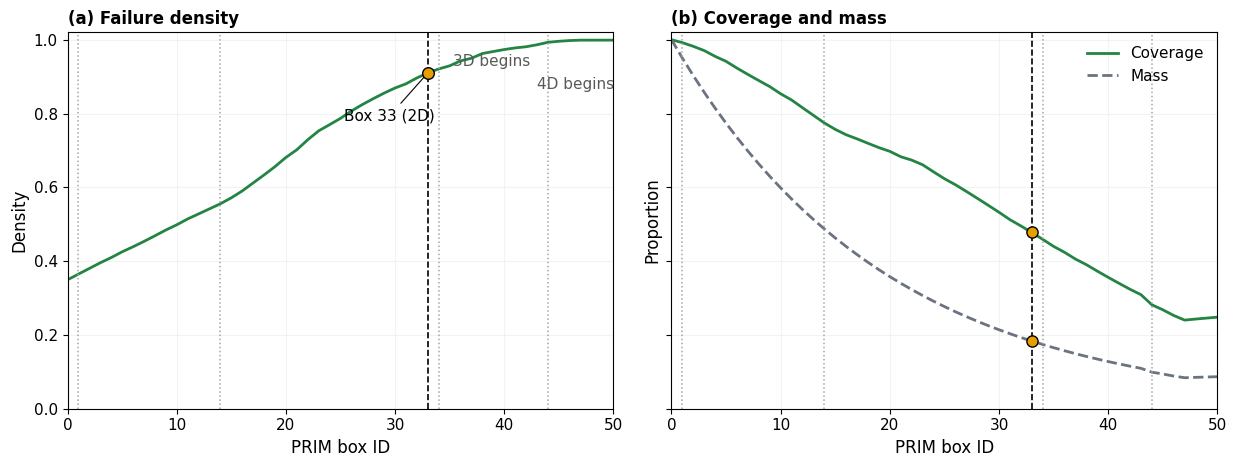

In [10]:
# 3.6 Scenario Discovery: Figure S21 and Table S13

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

results_dir = Path("PRIM_Results")

trajectory = pd.read_csv(results_dir / "prim_peeling_trajectory_S3.csv")
table_s13 = pd.read_csv(results_dir / "prim_candidate_boxes_S3.csv")

two_dimensional = trajectory.loc[trajectory["res_dim"].eq(2)]
selected_box = int(
    two_dimensional.loc[two_dimensional["density"].idxmax(), "box_id"]
)

selected = trajectory.set_index("box_id").loc[selected_box]
transitions = trajectory.loc[
    trajectory["res_dim"].diff().gt(0), "box_id"
].tolist()

# Table S13
print("\n" + "=" * 110)
print("TABLE S13 — PRIM CANDIDATE BOX COMPARISON")
print("=" * 110)

with pd.option_context("display.max_colwidth", None, "display.width", 220):
    print(table_s13.round(3).to_string(index=False))

# Figure S21
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 11,
    "axes.labelsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "axes.linewidth": 0.8,
    "legend.fontsize": 11,
})

fig, axes = plt.subplots(
    1, 2, figsize=(12.5, 4.8), sharex=True, sharey=True
)

x = trajectory["box_id"].to_numpy()

# (a) Failure density
ax = axes[0]

ax.plot(
    x, trajectory["density"],
    color="#238443", linewidth=2, label="Density"
)

ax.scatter(
    selected_box, selected["density"],
    s=70, color="#E69F00", edgecolor="black", zorder=5
)

ax.set_title("(a) Failure density", loc="left", fontweight="bold")
ax.set_xlabel("PRIM box ID")
ax.set_ylabel("Density")

ax.annotate(
    f"Box {selected_box} (2D)",
    xy=(selected_box, selected["density"]),
    xytext=(-60, -34),
    textcoords="offset points",
    arrowprops={"arrowstyle": "-", "color": "black", "linewidth": 0.8},
    fontsize=11,
)

# (b) Coverage and mass
ax = axes[1]

ax.plot(
    x, trajectory["coverage"],
    color="#238443", linewidth=2, label="Coverage"
)

ax.plot(
    x, trajectory["mass"],
    color="#6B7280", linewidth=2, linestyle="--", label="Mass"
)

for metric in ["coverage", "mass"]:
    ax.scatter(
        selected_box, selected[metric],
        s=65, color="#E69F00", edgecolor="black", zorder=5
    )

ax.set_title("(b) Coverage and mass", loc="left", fontweight="bold")
ax.set_xlabel("PRIM box ID")
ax.set_ylabel("Proportion")
ax.legend(frameon=False, loc="upper right")

# Selected box and dimension transitions
for ax in axes:
    ax.axvline(
        selected_box, color="black", linestyle="--", linewidth=1.2
    )

    for box_id in transitions:
        ax.axvline(
            box_id, color="0.65", linestyle=":", linewidth=1.1
        )

    ax.set_xlim(0, x.max())
    ax.set_ylim(0, 1.02)
    ax.grid(alpha=0.15)

for dimension, offset in [(3, (10, -16)), (4, (-8, -33))]:
    transition = trajectory.loc[trajectory["res_dim"].eq(dimension), "box_id"]

    if not transition.empty:
        axes[0].annotate(
            f"{dimension}D begins",
            xy=(transition.iloc[0], 0.99),
            xytext=offset,
            textcoords="offset points",
            fontsize=11,
            color="0.35",
        )

fig.tight_layout()
plt.show()